In [6]:
import sys
from pathlib import Path

PROJECT_ROOT = Path().resolve().parent

sys.path.append(str(PROJECT_ROOT))

In [7]:
import pickle
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from src.config.settings import MODEL_DIR

from src.proposed.model import ProposedV4
from src.baselines.b1_transformer.dataset import get_test_loader

In [9]:
# Load model
MODEL_PATH = MODEL_DIR / "proposed" / "proposed_v4.pt"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = ProposedV4()

model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device,
    )
)

model.to(device)
model.eval()

loader = get_test_loader(batch_size=16)

In [25]:
# discordance
all_trace = []

all_entropy = []

all_fidelity = []

all_purity = []

all_labels = []

all_gate = []

all_predictions = []

model.eval()

with torch.no_grad():

    for batch in loader:

        embeddings = batch["embedding_sequence"].to(device)

        attention_mask = batch["attention_mask"].to(device)

        labels = batch["label"]

        logits, diagnostics = model(

            embeddings,

            attention_mask,

        )

        all_trace.extend(

            diagnostics["trace_distance"]
            .cpu()
            .numpy()
        )

        all_entropy.extend(

            diagnostics["entropy_gap"]
            .cpu()
            .numpy()
        )

        all_fidelity.extend(

            diagnostics["fidelity"]
            .cpu()
            .numpy()
        )

        all_purity.extend(

            diagnostics["purity"]
            .cpu()
            .numpy()
        )

        all_gate.extend(

            diagnostics["gate_weights"]
            .mean(dim=1)
            .cpu()
            .numpy()
        )
        
        logits, diagnostics = model(
            embeddings,
            attention_mask,
        )
        
        predictions = torch.argmax(
            logits,
            dim=1,
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(

            labels.numpy()

        )

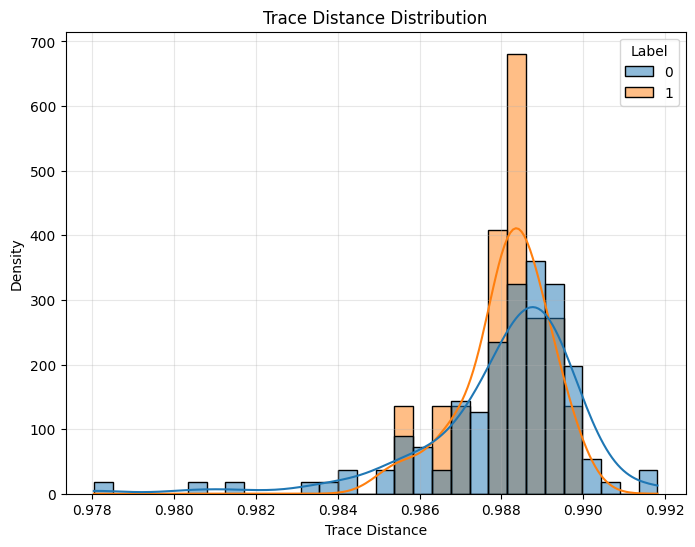

In [11]:
# Trace distrib
plt.figure(figsize=(8,6))

sns.histplot(
    data={
        "Trace Distance": all_trace,
        "Label": all_labels,
    },
    x="Trace Distance",
    hue="Label",
    bins=30,
    kde=True,
    stat="density",
    common_norm=False,
)

plt.title("Trace Distance Distribution")
plt.xlabel("Trace Distance")
plt.ylabel("Density")

plt.grid(alpha=0.3)

plt.show()

^Produces consistently high trace distances, indicating that the attention-derived semantic state and contextual semantic state are highly distinguishable, although the separation between classes remains modest.

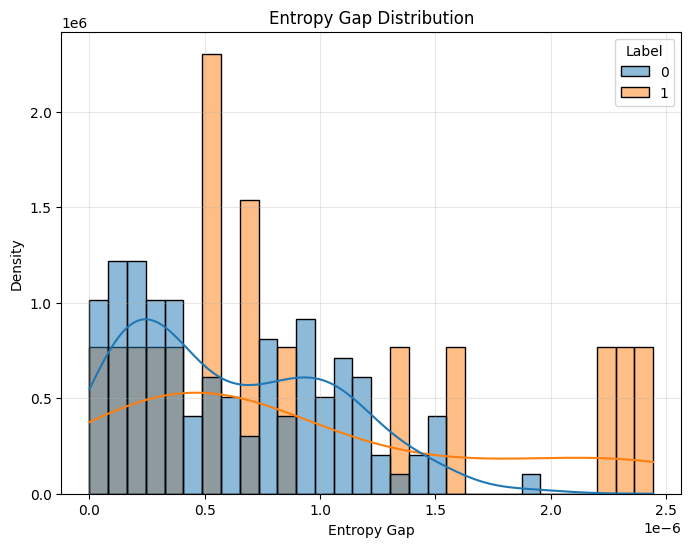

In [12]:
# Entropy gap distrib
plt.figure(figsize=(8,6))

sns.histplot(
    data={
        "Entropy Gap": all_entropy,
        "Label": all_labels,
    },
    x="Entropy Gap",
    hue="Label",
    bins=30,
    kde=True,
    stat="density",
    common_norm=False,
)

plt.title("Entropy Gap Distribution")
plt.xlabel("Entropy Gap")
plt.ylabel("Density")

plt.grid(alpha=0.3)

plt.show()

^The entropy gaps are extremely small: 10^-6. From Attention Pool → Projection → Normalise → Density. 

Both branches originate from the same DeBERTa embeddings and thus expected to have very similar entropy. The few orange outliers correspond to more semantically inconsistent depressed users.

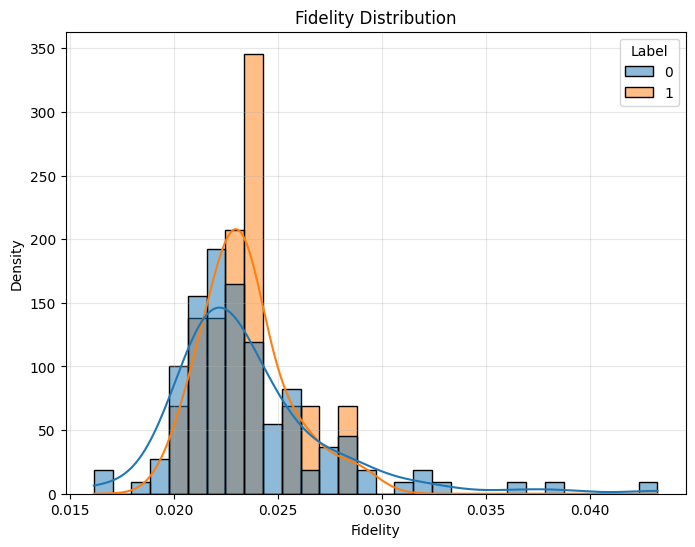

In [13]:
# Fidelity distrib
plt.figure(figsize=(8,6))

sns.histplot(
    data={
        "Fidelity": all_fidelity,
        "Label": all_labels,
    },
    x="Fidelity",
    hue="Label",
    bins=30,
    kde=True,
    stat="density",
    common_norm=False,
)

plt.title("Fidelity Distribution")
plt.xlabel("Fidelity")
plt.ylabel("Density")

plt.grid(alpha=0.3)

plt.show()

^There is variation. Since fidelity measures similarity, lower fidelity → higher semantic disagreement. The two classes overlap, and that's expected on a text-only dataset.

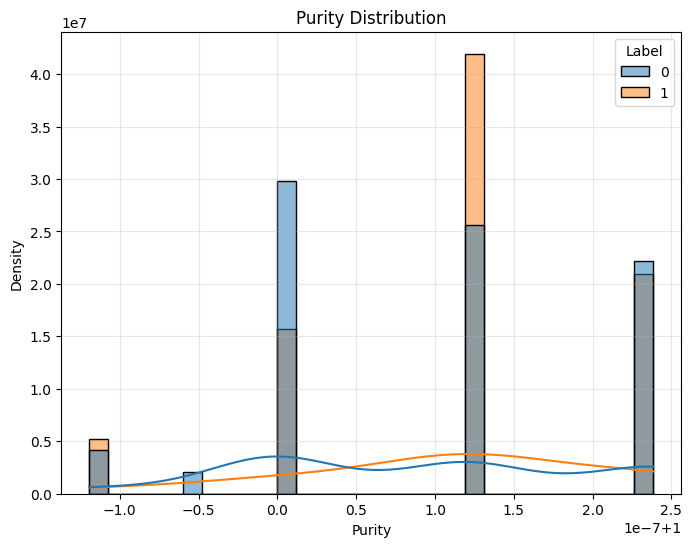

In [14]:
# Purity distrib
plt.figure(figsize=(8,6))

sns.histplot(
    data={
        "Purity": all_purity,
        "Label": all_labels,
    },
    x="Purity",
    hue="Label",
    bins=30,
    kde=True,
    stat="density",
    common_norm=False,
)

plt.title("Purity Distribution")
plt.xlabel("Purity")
plt.ylabel("Density")

plt.grid(alpha=0.3)

plt.show()

^Purity remained approximately one across all samples because density matrices were constructed from normalised state vectors, producing pure-state representations.

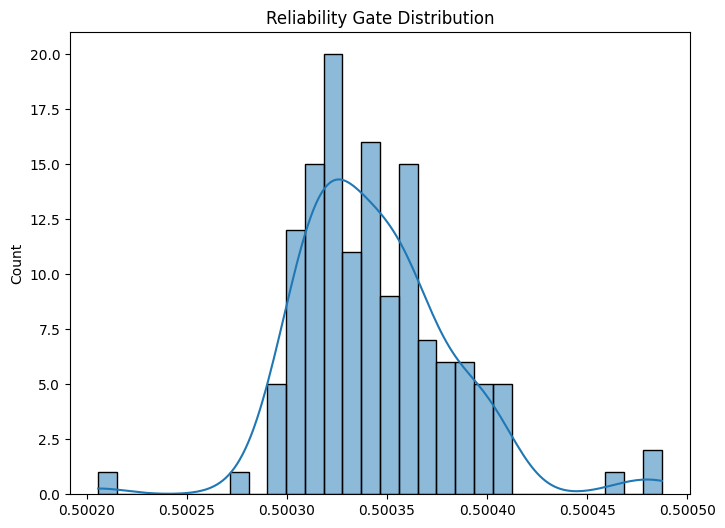

In [15]:
# Reliability Gate Distribution
plt.figure(figsize=(8,6))

sns.histplot(

    all_gate,

    bins=30,

    kde=True,

)

plt.title(

    "Reliability Gate Distribution"

)

plt.show()

^Mean = 0.50034 i.e very close to 0.5 and hence the gate isn't saturating which suggests the gate is behaving normally. 

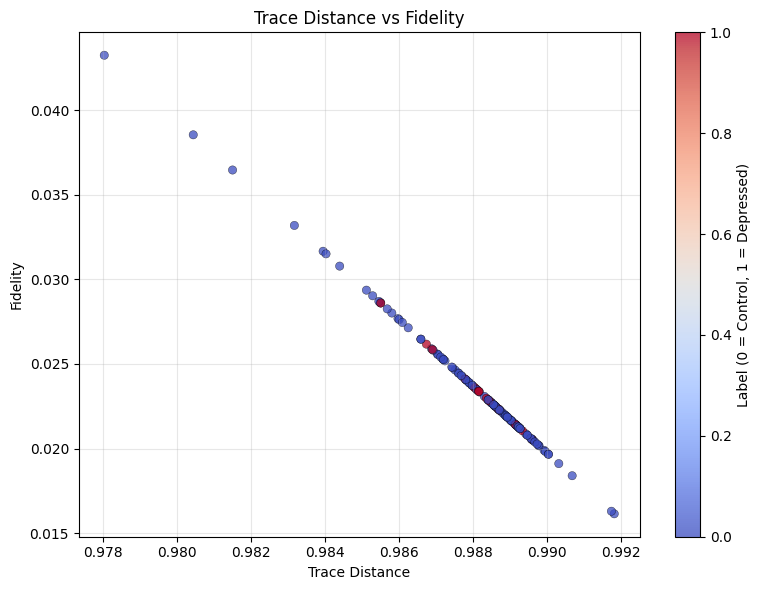

In [23]:
# Trace Distance vs Fidelity
plt.figure(figsize=(8,6))

scatter = plt.scatter(
    all_trace,
    all_fidelity,
    c=all_labels,
    cmap="coolwarm",
    alpha=0.75,
    edgecolors="k",
    linewidth=0.3,
)

plt.xlabel("Trace Distance")
plt.ylabel("Fidelity")

plt.title("Trace Distance vs Fidelity")

plt.grid(alpha=0.3)

cbar = plt.colorbar(scatter)

cbar.set_label(
    "Label (0 = Control, 1 = Depressed)"
)

plt.tight_layout()

plt.show()

As shown above, Trace Distance increases → Fidelity decreases almost perfectly which indicates the framework is internally consistent.

Model isn't producing random quantum metrics and agree with one another. Furthermore, explains the correlation matrix where:

Trace ↔ Fidelity

   -1.00

The scatter plot visually validates that.

§ Depression separation
Most points are blue. Some are red.
The red samples mostly lie inside the same manifold. This means the proposed model is not discovering an entirely different quantum regime for depressed users. Instead, measuring discordance consistently for every subject.

Note: The framework can quantify semantic discordance. 

Unimodal dataset → small discordance.

Multimodal dataset → larger discordance.

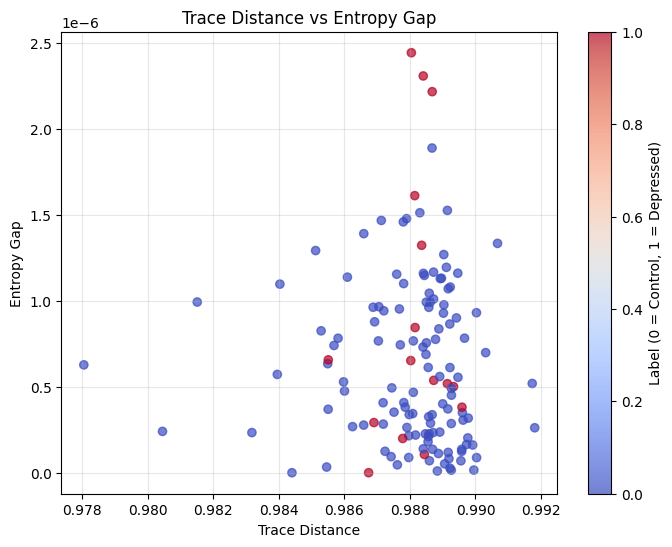

In [17]:
# Trace Distance vs Entropy
plt.figure(figsize=(8,6))

scatter = plt.scatter(
    all_trace,
    all_entropy,
    c=all_labels,
    cmap="coolwarm",
    alpha=0.7,
)

plt.xlabel("Trace Distance")
plt.ylabel("Entropy Gap")

plt.title("Trace Distance vs Entropy Gap")

plt.grid(alpha=0.3)

plt.colorbar(
    scatter,
    label="Label (0 = Control, 1 = Depressed)",
)

plt.show()

^No obvious clusters. Expected from a unimodal dataset.

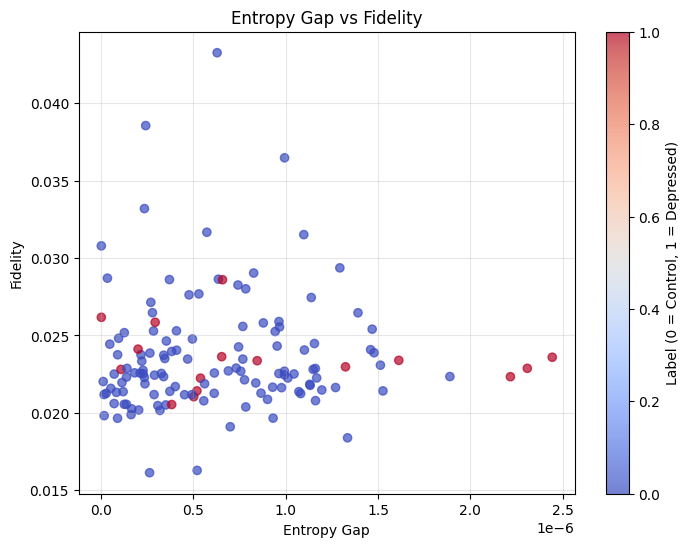

In [18]:
# Entropy vs Fidelity
plt.figure(figsize=(8,6))

scatter = plt.scatter(
    all_entropy,
    all_fidelity,
    c=all_labels,
    cmap="coolwarm",
    alpha=0.7,
)

plt.xlabel("Entropy Gap")
plt.ylabel("Fidelity")

plt.title("Entropy Gap vs Fidelity")

plt.grid(alpha=0.3)

plt.colorbar(
    scatter,
    label="Label (0 = Control, 1 = Depressed)",
)

plt.show()

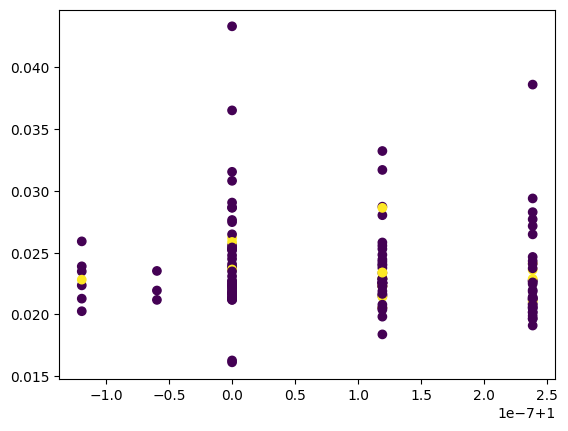

In [19]:
# Purity vs Fidelity
plt.scatter(

    all_purity,

    all_fidelity,

    c=all_labels,

)

^Not very informative, report purity in summary tables only. 

<Axes: >

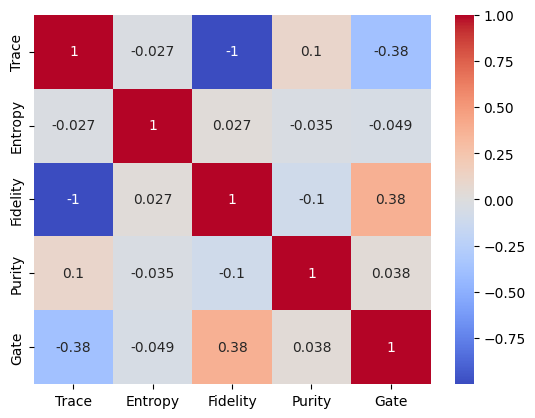

In [20]:
# Correlation matrix
metrics_df = pd.DataFrame({

    "Trace": all_trace,

    "Entropy": all_entropy,

    "Fidelity": all_fidelity,

    "Purity": all_purity,

    "Gate": all_gate,

})

sns.heatmap(

    metrics_df.corr(),

    annot=True,

    cmap="coolwarm",

)

^Trace → Fidelity
     -1.0

As higher trace distance → lower fidelity. Those are mathematically complementary notions of state similarity.

Gate → Trace

  -0.38

Gate → Fidelity

   +0.38

The reliability mechanism is responding to semantic similarity.

In [22]:
summary = pd.DataFrame({

    "Metric": [

        "Trace Distance",

        "Entropy Gap",

        "Fidelity",

        "Purity",

        "Gate",

    ],

    "Mean": [

        np.mean(all_trace),

        np.mean(all_entropy),

        np.mean(all_fidelity),

        np.mean(all_purity),

        np.mean(all_gate),

    ],

    "Std": [

        np.std(all_trace),

        np.std(all_entropy),

        np.std(all_fidelity),

        np.std(all_purity),

        np.std(all_gate),

    ],

    "Min": [

        np.min(all_trace),

        np.min(all_entropy),

        np.min(all_fidelity),

        np.min(all_purity),

        np.min(all_gate),

    ],

    "Max": [

        np.max(all_trace),

        np.max(all_entropy),

        np.max(all_fidelity),

        np.max(all_purity),

        np.max(all_gate),

    ],

})

summary

,Metric,Mean,Std,Min,Max
0,Trace Distance,9.880322e-01,1.878275e-03,9.780446e-01,0.991810
1,Entropy Gap,6.431962e-07,5.017467e-07,1.287844e-09,0.000002
2,Fidelity,2.361604e-02,3.704743e-03,1.613888e-02,0.043260
3,Purity,1.000000e+00,1.428589e-07,9.999999e-01,1.000000
4,Gate,5.003438e-01,3.811583e-05,5.002058e-01,0.500487


In [ ]:
# Classification
from sklearn.metrics import classification_report

print("=" * 60)
print("Classification Report")
print("=" * 60)

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=[
            "Control",
            "Depressed",
        ],
        digits=4,
    )
)

In [ ]:
# Confusion matrix
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    all_labels,
    all_predictions,
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Control",
        "Depressed",
    ],
)

fig, ax = plt.subplots(figsize=(6,6))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
)

plt.title("Confusion Matrix")

plt.tight_layout()

plt.show()